# 04 — Modelos Não Lineares: Árvores de Decisão e Random Forest

Até aqui usamos só a **regressão linear**. No notebook 03, com muito trabalho manual (atributos derivados, logaritmo, distância até as cidades), chegamos a **MAE de 0,464** no teste. Mas o modelo continuava limitado: ele só sabe desenhar retas, então qualquer relação curva precisava ser criada **por nós**.

Neste notebook vamos usar modelos que **descobrem sozinhos** relações não lineares. Você vai aprender:

- Como uma **árvore de decisão** funciona, e como ler uma
- Por que a árvore gera previsões em **"escada"**
- **Overfitting na prática**: uma árvore que decora o treino
- O que é um **hiperparâmetro** e a **curva de complexidade**
- **Random forest**: por que a média de muitas árvores funciona melhor
- **Importância dos atributos**

> Lembrete: execute as células em ordem com `Shift + Enter`.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ferramentas novas deste notebook:
from sklearn.tree import DecisionTreeRegressor, plot_tree   # árvore de decisão e função para desenhá-la
from sklearn.ensemble import RandomForestRegressor          # random forest (floresta aleatória)

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# Exatamente a mesma divisão do notebook 03: treino 60%, validação 20%, teste 20%.
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

print(f"Treino: {len(X_train)}   Validação: {len(X_val)}   Teste: {len(X_test)} (guardado!)")

Treino: 12384   Validação: 4128   Teste: 4128 (guardado!)


In [2]:
def avaliar(y_real, y_previsto):
    """Calcula MAE, RMSE e R² e devolve tudo num dicionário."""
    mae = mean_absolute_error(y_real, y_previsto)
    rmse = np.sqrt(mean_squared_error(y_real, y_previsto))
    r2 = r2_score(y_real, y_previsto)
    return {"MAE": round(float(mae), 3), "RMSE": round(float(rmse), 3), "R²": round(float(r2), 3)}


# Resultados na validação. Os dois primeiros foram copiados do notebook 03,
# que usou exatamente esta mesma divisão de dados.
resultados_val = {
    "Linear simples (nb 02)": {"MAE": 0.533, "RMSE": 0.728, "R²": 0.614},
    "Linear + pré-processamento (nb 03)": {"MAE": 0.465, "RMSE": 0.638, "R²": 0.704},
}
pd.DataFrame(resultados_val).T

,MAE,RMSE,R²
Linear simples (nb 02),0.533,0.728,0.614
Linear + pré-processamento (nb 03),0.465,0.638,0.704


**Conclusão:** este é o placar a ser batido na validação: **MAE 0,465**, o melhor resultado do notebook 03.

## 🎓 Conceito: árvore de decisão

Lembra do jogo de **"20 perguntas"**? Você descobre algo fazendo perguntas de sim/não, uma depois da outra. Uma **árvore de decisão** faz exatamente isso:

```
                    A renda é ≤ 5,0?
                   /                \
                 sim                não
                 /                    \
     A renda é ≤ 3,1?          A renda é ≤ 6,9?
       /        \                 /        \
   prevê 1,35  prevê 2,08    prevê 2,92  prevê 4,25
```

Vocabulário:
- **Nó**: cada pergunta.
- **Folha**: o fim de um caminho, onde não há mais perguntas. A previsão é a **média do alvo** das casas de treino que chegaram até ali.
- **Profundidade**: quantas perguntas existem no caminho mais longo. Na figura, 2.

**Como a árvore escolhe as perguntas?** No treino, ela testa muitas perguntas possíveis (cada coluna, cada valor de corte) e escolhe a que **separa melhor** as casas em dois grupos de preços parecidos, ou seja, a que mais reduz o erro. Depois repete o processo dentro de cada grupo.

Vamos começar com uma árvore pequena, usando só a renda, para conseguir ler.

## 2. Uma árvore pequena com uma variável

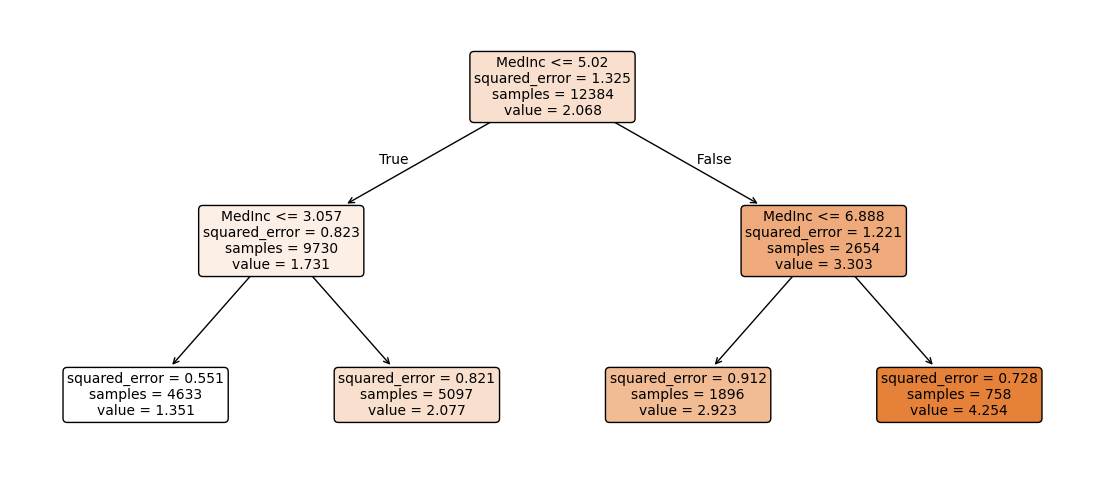

In [3]:
# max_depth=2 limita a árvore a 2 níveis de perguntas.
# random_state=42 garante o mesmo resultado sempre (em empates, a árvore sorteia).
arvore_pequena = DecisionTreeRegressor(max_depth=2, random_state=42)
arvore_pequena.fit(X_train[["MedInc"]], y_train)

# plot_tree desenha a árvore.
#   feature_names -> nomes das colunas, para aparecerem nas perguntas
#   filled=True   -> pinta as caixas: quanto mais escura, maior o valor previsto
#   rounded=True  -> caixas com cantos arredondados
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arvore_pequena, feature_names=["MedInc"], filled=True, rounded=True, ax=ax, fontsize=10)
plt.show()

**Como ler cada caixa:**
- **1ª linha:** a pergunta (ex.: `MedInc <= 5.02`). Se a resposta for **sim**, siga para a **esquerda**; se for **não**, para a **direita**.
- **`squared_error`:** o erro quadrático médio das casas naquela caixa. Quanto menor, mais parecidos são os preços do grupo.
- **`samples`:** quantas casas do treino chegaram ali.
- **`value`:** a previsão, ou seja, a média de `MedHouseVal` dessas casas.

**Conclusão:** a árvore aprendeu sozinha 4 faixas de renda, cada uma com um preço: renda até 3,06 → 1,35 (US\$ 135 mil); de 3,06 a 5,02 → 2,08; de 5,02 a 6,89 → 2,92; acima de 6,89 → 4,25. Repare que os cortes **não são igualmente espaçados**: a árvore escolheu os pontos que melhor separam os preços.

## 3. Previsões em "escada"

No notebook 02, usamos o truque do `np.linspace` para desenhar a **reta** da regressão linear. Vamos repetir com árvores de profundidades diferentes.

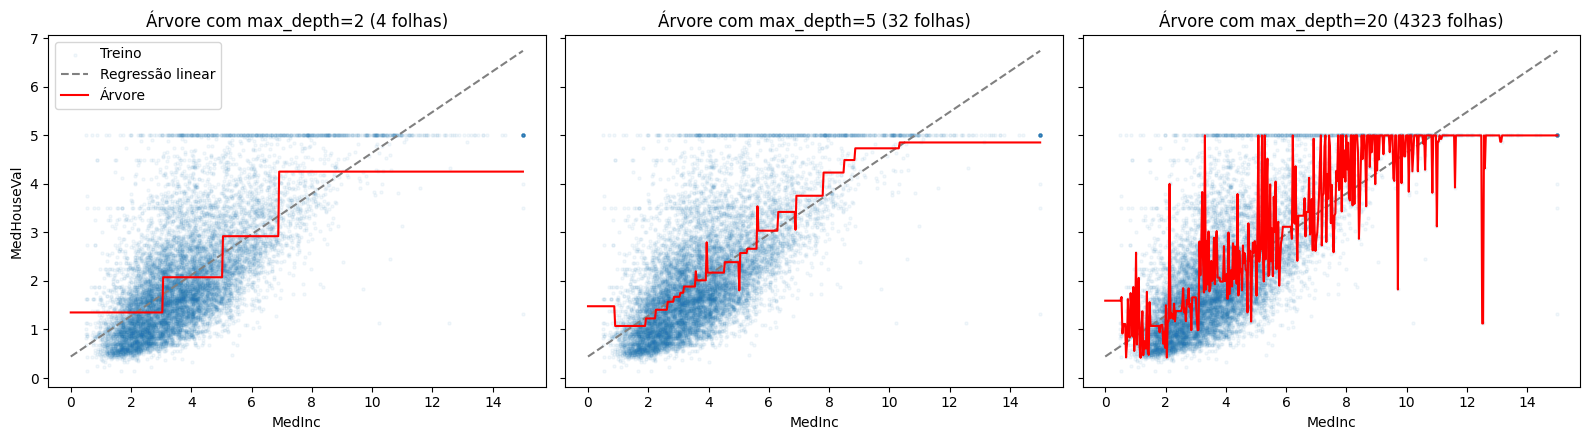

In [4]:
renda_grid = pd.DataFrame({"MedInc": np.linspace(0, 15, 500)})

# Para comparar, a regressão linear com uma variável (a mesma do notebook 02).
linear_renda = LinearRegression().fit(X_train[["MedInc"]], y_train)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)   # sharey: mesmo eixo y nos 3 gráficos

for ax, profundidade in zip(axes, [2, 5, 20]):
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=42)
    arvore.fit(X_train[["MedInc"]], y_train)

    ax.scatter(X_train["MedInc"], y_train, alpha=0.05, s=5, label="Treino")
    ax.plot(renda_grid["MedInc"], linear_renda.predict(renda_grid), color="gray",
            linestyle="--", label="Regressão linear")
    ax.plot(renda_grid["MedInc"], arvore.predict(renda_grid), color="red", label="Árvore")
    ax.set_title(f"Árvore com max_depth={profundidade} ({arvore.get_n_leaves()} folhas)")
    ax.set_xlabel("MedInc")

axes[0].set_ylabel("MedHouseVal")
axes[0].legend()
plt.tight_layout()
plt.show()

**Conclusão:**
- **Profundidade 2:** uma escada com 4 degraus, as 4 folhas que lemos acima. Grosseira, mas já captura a tendência.
- **Profundidade 5:** 32 degraus que acompanham bem os dados, inclusive a **curva** que a reta não consegue seguir. Para rendas altas, a escada "achata" perto de 5,0, respeitando o teto.
- **Profundidade 20:** a escada fica **nervosa**, com subidas e descidas bruscas. Ela está reagindo a casas individuais (ruído), não à tendência geral. Isso é sinal de **overfitting**, que vamos medir a seguir.

Repare também: a árvore **nunca passa de 5,0 nem fica negativa**. Cada previsão é a média de casas reais, então ela sempre fica dentro do intervalo visto no treino. O problema das previsões impossíveis do notebook 03 some sozinho.

## 4. Árvore com todas as colunas, sem limite de profundidade

In [5]:
# Sem max_depth, a árvore continua fazendo perguntas até cada folha ficar "pura"
# (normalmente com uma única casa).
arvore_livre = DecisionTreeRegressor(random_state=42)
arvore_livre.fit(X_train, y_train)

print(f"Profundidade: {arvore_livre.get_depth()}")
print(f"Folhas:       {arvore_livre.get_n_leaves()}  (o treino tem {len(X_train)} casas)")
print("Treino:   ", avaliar(y_train, arvore_livre.predict(X_train)))
print("Validação:", avaliar(y_val, arvore_livre.predict(X_val)))

Profundidade: 33
Folhas:       11901  (o treino tem 12384 casas)
Treino:    {'MAE': 0.0, 'RMSE': 0.0, 'R²': 1.0}
Validação: {'MAE': 0.454, 'RMSE': 0.706, 'R²': 0.637}


**Conclusão: este é o overfitting na sua forma mais pura.**

- No **treino**, o erro é **zero** (MAE 0,000, R² 1,0). A árvore criou quase 12 mil folhas para 12 mil casas, ou seja, praticamente **uma folha por casa**. Ela **decorou** o treino, como o aluno que decora a lista de exercícios.
- Na **validação**, o MAE é 0,454. É bom (já ganha da regressão linear do notebook 03!), mas está muito longe do "perfeito" do treino.

A distância entre o treino e a validação é o **tamanho do overfitting**. Se olhássemos só o treino, acharíamos que o modelo é perfeito. É por isso que **nunca** avaliamos um modelo nos dados em que ele treinou.

## 🎓 Conceito: hiperparâmetros

O `max_depth` é um **hiperparâmetro**: uma configuração que **nós** escolhemos **antes** de treinar. Compare com os **parâmetros**, que o modelo **aprende** sozinho durante o `.fit()`:

| | Quem define | Exemplos |
|---|---|---|
| **Parâmetros** | O modelo, no treino | Coeficientes da regressão linear; as perguntas e os cortes da árvore |
| **Hiperparâmetros** | Nós, antes do treino | `max_depth` da árvore; `n_estimators` da random forest (que veremos adiante) |

Como escolher um bom hiperparâmetro? **Testando vários valores e comparando na validação.** Para o `max_depth`, isso gera a **curva de complexidade**.

## 5. Curva de complexidade: qual a melhor profundidade?

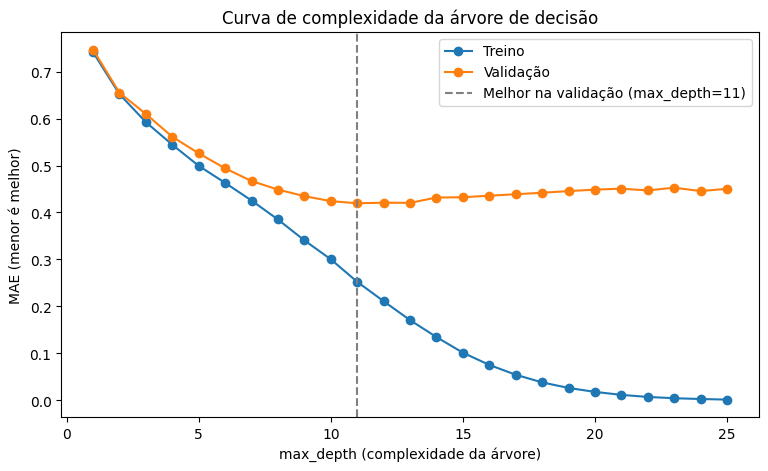

Melhor max_depth: 11  ->  MAE na validação: 0.420


In [6]:
profundidades = range(1, 26)   # testa max_depth de 1 a 25
mae_treino = []
mae_val = []

for profundidade in profundidades:
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=42)
    arvore.fit(X_train, y_train)
    mae_treino.append(mean_absolute_error(y_train, arvore.predict(X_train)))
    mae_val.append(mean_absolute_error(y_val, arvore.predict(X_val)))

# np.argmin devolve a POSIÇÃO do menor valor da lista.
melhor_pos = np.argmin(mae_val)
melhor_profundidade = profundidades[melhor_pos]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(profundidades, mae_treino, marker="o", label="Treino")
ax.plot(profundidades, mae_val, marker="o", label="Validação")
ax.axvline(melhor_profundidade, color="gray", linestyle="--",
           label=f"Melhor na validação (max_depth={melhor_profundidade})")
ax.set_xlabel("max_depth (complexidade da árvore)")
ax.set_ylabel("MAE (menor é melhor)")
ax.set_title("Curva de complexidade da árvore de decisão")
ax.legend()
plt.show()

print(f"Melhor max_depth: {melhor_profundidade}  ->  MAE na validação: {mae_val[melhor_pos]:.3f}")

**Conclusão:** este gráfico resume os conceitos de **underfitting** e **overfitting** do notebook 02:

- **À esquerda (profundidade baixa):** treino e validação têm erro **alto e parecido**. A árvore é simples demais: **underfitting**.
- **No meio (profundidade 11):** a validação atinge o **menor erro**, MAE 0,420. É o ponto de equilíbrio.
- **À direita (profundidade alta):** o erro do treino continua caindo até zero, mas o da validação **para de cair e piora**. A árvore está decorando ruído: **overfitting**.

A regra prática é **escolher a complexidade pelo erro da validação, nunca pelo do treino**. O erro do treino *sempre* melhora com mais complexidade, então ele não serve para essa decisão.

In [7]:
# Guardamos a árvore com a melhor profundidade.
melhor_arvore = DecisionTreeRegressor(max_depth=melhor_profundidade, random_state=42)
melhor_arvore.fit(X_train, y_train)
resultados_val[f"Árvore (max_depth={melhor_profundidade})"] = avaliar(y_val, melhor_arvore.predict(X_val))
resultados_val[f"Árvore (max_depth={melhor_profundidade})"]

{'MAE': 0.42, 'RMSE': 0.644, 'R²': 0.698}

**Conclusão:** uma única árvore, **sem nenhum pré-processamento**, tem MAE de **0,420** contra 0,465 do notebook 03. Em média, ela erra menos que todo o nosso trabalho manual.

⚠️ Mas compare as outras métricas: o **RMSE** da árvore (0,644) é um pouco **maior** que o do notebook 03 (0,638), e o R² é um pouco menor (0,698 contra 0,704). Como isso é possível? Lembre do notebook 02: o RMSE **pune mais os erros grandes**. A árvore acerta melhor a maioria das casas, mas, quando erra, às vezes erra feio, porque uma pergunta errada no topo manda a casa para uma folha totalmente diferente.

**Lição:** cada métrica conta uma parte da história. Por isso olhamos mais de uma.

## 6. Três propriedades importantes das árvores

**a) Não precisam de padronização.** Uma pergunta como "renda ≤ 5,02?" funciona igual em qualquer escala. Se padronizarmos, o corte só muda para "renda padronizada ≤ 0,61", e as casas vão para o mesmo lado.

In [8]:
arvore_padronizada = Pipeline([
    ("padronizar", StandardScaler()),
    ("modelo", DecisionTreeRegressor(max_depth=melhor_profundidade, random_state=42)),
])
arvore_padronizada.fit(X_train, y_train)

print("Sem padronizar:", avaliar(y_val, melhor_arvore.predict(X_val)))
print("Padronizada:   ", avaliar(y_val, arvore_padronizada.predict(X_val)))

Sem padronizar: {'MAE': 0.42, 'RMSE': 0.644, 'R²': 0.698}
Padronizada:    {'MAE': 0.42, 'RMSE': 0.646, 'R²': 0.696}


**Conclusão:** o resultado é o mesmo. A diferença fica na 3ª casa decimal, quando aparece, e vem de arredondamentos do computador ao comparar números muito próximos, não do modelo. Padronizar árvores é trabalho à toa.

**b) Também não precisam de logaritmo.** Pelo mesmo motivo: o log "comprime" os valores, mas **não muda a ordem** deles. Se a > b, então log(a) > log(b). Como a árvore só faz perguntas do tipo "maior ou menor que?", as casas continuam sendo separadas da mesma forma. As caudas longas que atrapalhavam a regressão linear não incomodam a árvore.

**c) Mostram quais colunas usaram mais.**

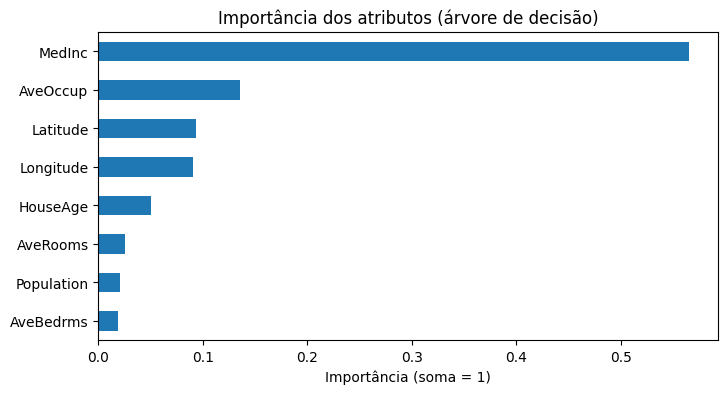

MedInc        0.565
AveOccup      0.136
Latitude      0.094
Longitude     0.091
HouseAge      0.050
AveRooms      0.025
Population    0.020
AveBedrms     0.019
dtype: float64

In [9]:
# feature_importances_: quanto cada coluna contribuiu para reduzir o erro, somando
# todas as perguntas em que ela foi usada. Os valores somam 1 (ou seja, 100%).
importancias_arvore = pd.Series(melhor_arvore.feature_importances_, index=X_train.columns)
importancias_arvore.sort_values().plot.barh(figsize=(8, 4))
plt.title("Importância dos atributos (árvore de decisão)")
plt.xlabel("Importância (soma = 1)")
plt.show()

importancias_arvore.sort_values(ascending=False).round(3)

**Conclusão:** `MedInc` responde por **mais da metade** (56%) da redução do erro, confirmando o que a correlação mostrou no notebook 01.

A surpresa é `AveOccup`, em 2º lugar (14%). No notebook 01, sua correlação com o preço era quase **zero** (−0,02)! Isso mostra o limite da correlação de Pearson: ela só mede relações **lineares**. A árvore encontrou uma relação **não linear** que a correlação não enxerga. `Latitude` e `Longitude` vêm logo depois, cada uma com ~9%.

⚠️ Importância indica **quanto** a árvore usou a coluna, **não a direção** do efeito (se aumenta ou diminui o preço).

## 🎓 Conceito: random forest (floresta aleatória)

Uma árvore sozinha tem um problema: ela é **instável**. Pequenas mudanças nos dados de treino podem gerar uma árvore bem diferente. Cada árvore comete erros "à sua maneira".

A ideia da **random forest** vem da **sabedoria das multidões**. Se você pedir a 100 pessoas para estimarem o peso de um boi, cada uma erra bastante, mas a **média** dos palpites costuma ficar muito perto do valor real. Os erros individuais, para cima e para baixo, **se cancelam**.

A random forest treina **muitas árvores diferentes** e faz a **média** das previsões. Para que as árvores sejam diferentes entre si, ela usa duas fontes de aleatoriedade:

1. **Amostras diferentes (*bootstrap*):** cada árvore treina com um "sorteio com reposição" das casas do treino. Algumas casas aparecem repetidas, e outras ficam de fora.
2. **Colunas diferentes:** em cada pergunta, a árvore só pode escolher entre parte das colunas. (No scikit-learn, isso é controlado pelo hiperparâmetro `max_features`.)

Essa técnica de combinar vários modelos se chama **ensemble** ("conjunto"). As árvores da floresta normalmente crescem **sem limite de profundidade**: cada uma tem overfitting, mas a média corrige grande parte dele.

## 7. Nossa primeira random forest

In [10]:
# n_estimators=100 -> número de árvores na floresta
# n_jobs=-1        -> usa todos os núcleos do processador para treinar árvores em paralelo (mais rápido)
# random_state=42  -> fixa os sorteios para o resultado ser reproduzível
floresta = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
floresta.fit(X_train, y_train)

resultados_val["Random forest (100 árvores)"] = avaliar(y_val, floresta.predict(X_val))
print("Treino:   ", avaliar(y_train, floresta.predict(X_train)))
print("Validação:", resultados_val["Random forest (100 árvores)"])

Treino:    {'MAE': 0.124, 'RMSE': 0.191, 'R²': 0.973}
Validação: {'MAE': 0.335, 'RMSE': 0.51, 'R²': 0.811}


**Conclusão:** o MAE na validação caiu para **0,335** (≈ US\$ 33.500), contra 0,420 da melhor árvore individual e 0,465 do notebook 03. O R² saltou para **0,81**. É o maior ganho de toda a trilha até agora.

Repare no treino: MAE de 0,124, ainda bem menor que a validação. Há overfitting, mas a pergunta que importa é se o erro da **validação** é bom, e ele é o melhor até aqui. Vamos tentar reduzir essa diferença ajustando hiperparâmetros no notebook 06.

Será que é mesmo a média que faz a mágica? Vamos olhar as árvores individuais.

In [11]:
# floresta.estimators_ é a lista com as 100 árvores treinadas.
# .values converte a tabela em array: as árvores internas foram treinadas sem nomes de colunas.
erros_individuais = [
    mean_absolute_error(y_val, arvore.predict(X_val.values))
    for arvore in floresta.estimators_
]

print(f"MAE de cada árvore sozinha: entre {min(erros_individuais):.3f} e {max(erros_individuais):.3f}")
print(f"MAE médio das árvores:      {np.mean(erros_individuais):.3f}")
print(f"MAE da MÉDIA das previsões: {mean_absolute_error(y_val, floresta.predict(X_val)):.3f}  <- a floresta")

MAE de cada árvore sozinha: entre 0.456 e 0.537
MAE médio das árvores:      0.493
MAE da MÉDIA das previsões: 0.335  <- a floresta


**Conclusão:** cada árvore sozinha erra, em média, **0,49**, pior até que uma árvore comum (0,42), porque cada uma treinou com uma amostra sorteada e com colunas limitadas. Mas a **média das previsões** delas erra só **0,335**.

Isso é a sabedoria das multidões em ação: **modelos individualmente piores, combinados, ficam muito melhores**. Só funciona porque as árvores erram de formas *diferentes*. Se fossem todas iguais, a média não ajudaria em nada.

## 8. Quantas árvores são necessárias?

   1 árvores: MAE 0.485  (0.1 s)


   5 árvores: MAE 0.377  (0.1 s)


  10 árvores: MAE 0.357  (0.2 s)


  25 árvores: MAE 0.342  (0.7 s)


  50 árvores: MAE 0.338  (0.8 s)


 100 árvores: MAE 0.335  (1.5 s)


 200 árvores: MAE 0.335  (3.0 s)


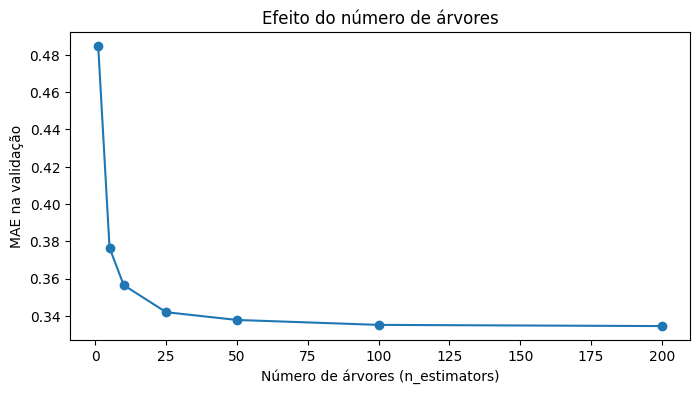

In [12]:
import time   # módulo para medir tempo

numeros_de_arvores = [1, 5, 10, 25, 50, 100, 200]
mae_por_n = []

for n in numeros_de_arvores:
    inicio = time.time()   # marca o horário antes de treinar
    modelo = RandomForestRegressor(n_estimators=n, n_jobs=-1, random_state=42)
    modelo.fit(X_train, y_train)
    mae_por_n.append(mean_absolute_error(y_val, modelo.predict(X_val)))
    print(f"{n:>4} árvores: MAE {mae_por_n[-1]:.3f}  ({time.time() - inicio:.1f} s)")   # [-1] = último item

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(numeros_de_arvores, mae_por_n, marker="o")
ax.set_xlabel("Número de árvores (n_estimators)")
ax.set_ylabel("MAE na validação")
ax.set_title("Efeito do número de árvores")
plt.show()

**Conclusão:** de 1 para 10 árvores, o erro cai muito (de ~0,48 para ~0,36). Depois disso, os ganhos ficam cada vez menores, e entre 100 e 200 árvores praticamente não há diferença. O tempo de treino, por outro lado, cresce na proporção do número de árvores.

Diferente do `max_depth`, **mais árvores nunca causam overfitting**: o erro só estabiliza. O preço é só o tempo. 100 árvores é um bom equilíbrio para este dataset.

## 9. A engenharia de atributos ainda ajuda?

A floresta não precisa de padronização nem de logaritmo. Mas e as **colunas novas** do notebook 03 (as proporções e a distância até as cidades)? Elas trazem **informação nova**, como combinações entre colunas, algo que uma árvore também tem dificuldade de descobrir sozinha. Vamos testar.

Reescrevemos as funções do notebook 03 (as mesmas, sem o logaritmo, que não faz diferença para árvores).

In [13]:
SAO_FRANCISCO = (37.77, -122.42)
LOS_ANGELES = (34.05, -118.24)


def criar_derivados(X):
    """Proporções: quartos por cômodo e cômodos por morador."""
    X = X.copy()
    X["BedrmsPerRoom"] = X["AveBedrms"] / X["AveRooms"]
    X["RoomsPerPerson"] = X["AveRooms"] / X["AveOccup"]
    return X


def criar_dist_cidade(X):
    """Distância aproximada (em graus) até a cidade grande mais próxima."""
    X = X.copy()
    dist_sf = np.sqrt((X["Latitude"] - SAO_FRANCISCO[0]) ** 2 + (X["Longitude"] - SAO_FRANCISCO[1]) ** 2)
    dist_la = np.sqrt((X["Latitude"] - LOS_ANGELES[0]) ** 2 + (X["Longitude"] - LOS_ANGELES[1]) ** 2)
    X["DistCidade"] = np.minimum(dist_sf, dist_la)
    return X


floresta_atributos = Pipeline([
    ("derivados", FunctionTransformer(criar_derivados)),
    ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
    ("modelo", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
])
floresta_atributos.fit(X_train, y_train)

resultados_val["Random forest + atributos do nb 03"] = avaliar(y_val, floresta_atributos.predict(X_val))
resultados_val["Random forest + atributos do nb 03"]

{'MAE': 0.316, 'RMSE': 0.484, 'R²': 0.829}

**Conclusão:** sim! O MAE caiu de 0,335 para **0,316**, e o R² chegou a 0,83.

A lição é que **pré-processamento e engenharia de atributos são coisas diferentes**:
- Padronização e logaritmo **mudam a escala** de colunas que já existem. A árvore não precisa disso.
- Colunas derivadas trazem **informação nova** (divisões entre colunas, distâncias). Qualquer modelo pode se beneficiar.

Conhecer o problema continua valendo a pena, mesmo com modelos mais poderosos.

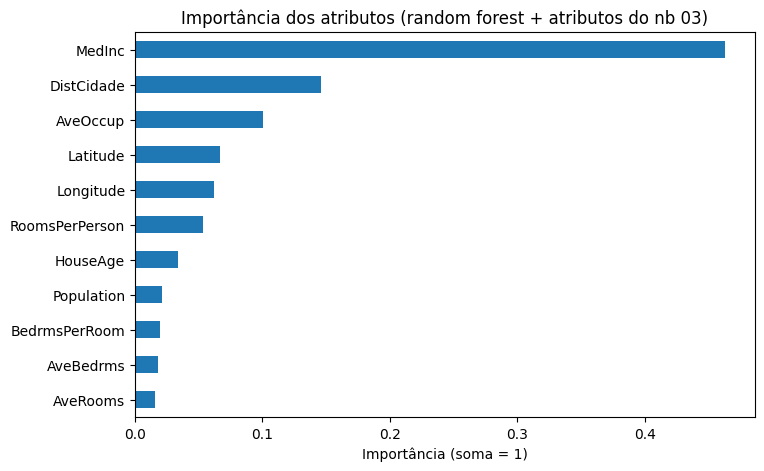

In [14]:
# Importância dos atributos na floresta com as colunas novas.
# floresta_atributos["modelo"] acessa a etapa da floresta dentro do pipeline.
# Para pegar os nomes das colunas, passamos uma linha pelas etapas de criação ([:-1] = todas menos o modelo).
nomes_colunas = floresta_atributos[:-1].transform(X_train.head(1)).columns
importancias = pd.Series(floresta_atributos["modelo"].feature_importances_, index=nomes_colunas)

importancias.sort_values().plot.barh(figsize=(8, 5))
plt.title("Importância dos atributos (random forest + atributos do nb 03)")
plt.xlabel("Importância (soma = 1)")
plt.show()

**Conclusão:** `MedInc` continua na liderança (46%), mas a grande novidade é `DistCidade`, a coluna que **criamos**: ela virou a **2ª mais importante** (15%). Repare que `Latitude` e `Longitude` caíram de ~9% para ~6% cada. A floresta passou a preferir a distância, que resume numa única pergunta ("está perto de SF ou LA?") o que antes exigia várias perguntas combinando latitude e longitude.

Já `BedrmsPerRoom` quase não foi usada (2%): nem toda coluna criada ajuda todos os modelos. Ela era útil para a regressão linear, mas a floresta encontra essa informação por outros caminhos.

## 10. E as casas no teto?

In [15]:
# Mesma análise do notebook 03: erro separado nas casas no teto e nas demais.
no_teto = y_val >= 5
previsoes_floresta = floresta_atributos.predict(X_val)

print(f"MAE casas normais: {mean_absolute_error(y_val[~no_teto], previsoes_floresta[~no_teto]):.3f}   (nb 03: 0,440)")
print(f"MAE casas no teto: {mean_absolute_error(y_val[no_teto], previsoes_floresta[no_teto]):.3f}   (nb 03: 1,175)")

MAE casas normais: 0.301   (nb 03: 0,440)
MAE casas no teto: 0.594   (nb 03: 1,175)


**Conclusão:** o erro nas casas do teto **caiu pela metade** em relação à regressão linear do notebook 03, e nas casas normais também caiu bastante. A floresta consegue isolar as regiões caras (perto do litoral, renda alta) com suas perguntas.

O erro no teto continua sendo bem maior que o das casas normais. Parte disso é **impossível de corrigir**: para essas casas, o valor real é desconhecido (sabemos só que é "5,0 ou mais").

## 11. Comparando todos os modelos (validação)

In [16]:
comparacao = pd.DataFrame(resultados_val).T.sort_values("MAE", ascending=False)
comparacao

,MAE,RMSE,R²
Linear simples (nb 02),0.533,0.728,0.614
Linear + pré-processamento (nb 03),0.465,0.638,0.704
Árvore (max_depth=11),0.420,0.644,0.698
Random forest (100 árvores),0.335,0.510,0.811
Random forest + atributos do nb 03,0.316,0.484,0.829


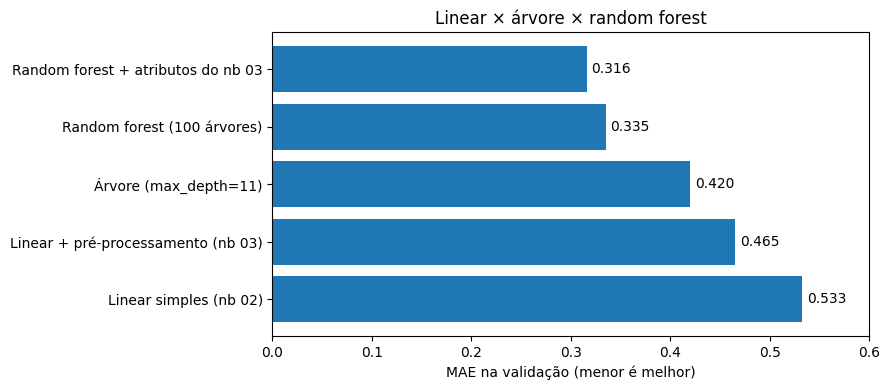

In [17]:
ordenado = comparacao["MAE"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ordenado.index, ordenado.values)
ax.set_xlabel("MAE na validação (menor é melhor)")
ax.set_title("Linear × árvore × random forest")
for i, valor in enumerate(ordenado.values):
    ax.text(valor + 0.005, i, f"{valor:.3f}", va="center")
ax.set_xlim(0, 0.6)   # aqui o eixo começa no zero: as diferenças aparecem no tamanho real
plt.tight_layout()
plt.show()

**Conclusão:** cada família de modelos deu um salto:
- **Linear → árvore:** 0,465 → 0,420. Uma única árvore erra menos em média que todo o trabalho manual (mas tem RMSE parecido, como vimos na seção 5).
- **Árvore → floresta:** 0,420 → 0,335. A média de muitas árvores corrige a instabilidade de cada uma.
- **Floresta + atributos:** 0,316. Conhecer o problema ainda ajuda.

Desta vez o eixo começa no **zero**, então as barras mostram as diferenças no tamanho real. Mesmo assim, a vantagem da floresta é bem visível.

## 12. Avaliação final no teste

Escolhemos o melhor modelo **pela validação**: a **random forest com os atributos do notebook 03**. Como no notebook 03, retreinamos com treino + validação e avaliamos no teste **uma única vez**.

Também incluímos a melhor árvore individual, para ver se a diferença entre elas se confirma em dados novos.

In [18]:
from sklearn.base import clone   # cria cópias "zeradas" (não treinadas) de um modelo

modelos_finais = {
    f"Árvore (max_depth={melhor_profundidade})": clone(melhor_arvore),
    "Random forest + atributos do nb 03": clone(floresta_atributos),
}

resultados_teste = {
    # Resultados no teste dos notebooks anteriores (mesma divisão de dados):
    "Linear simples (nb 02)": {"MAE": 0.533, "RMSE": 0.746, "R²": 0.576},
    "Linear + pré-processamento (nb 03)": {"MAE": 0.464, "RMSE": 0.644, "R²": 0.684},
}
for nome, modelo in modelos_finais.items():
    modelo.fit(X_train_full, y_train_full)   # treino + validação
    resultados_teste[nome] = avaliar(y_test, modelo.predict(X_test))

pd.DataFrame(resultados_teste).T

,MAE,RMSE,R²
Linear simples (nb 02),0.533,0.746,0.576
Linear + pré-processamento (nb 03),0.464,0.644,0.684
Árvore (max_depth=11),0.426,0.651,0.676
Random forest + atributos do nb 03,0.306,0.477,0.826


In [19]:
mae_03 = resultados_teste["Linear + pré-processamento (nb 03)"]["MAE"]
mae_04 = resultados_teste["Random forest + atributos do nb 03"]["MAE"]

print(f"Redução do erro em relação ao nb 03: {(mae_03 - mae_04) / mae_03:.1%}")
print(f"Em dólares: de US$ {mae_03 * 100_000:,.0f} para US$ {mae_04 * 100_000:,.0f}")

Redução do erro em relação ao nb 03: 34.1%
Em dólares: de US$ 46,400 para US$ 30,600


**Conclusão:** no teste, a random forest com os atributos do notebook 03 chegou a **MAE de 0,306** (≈ US\$ 30.600) e **R² de 0,83**. São **34% menos erro** que o melhor modelo linear (US\$ 46.400).

O resultado no teste ficou próximo do da validação (0,316), um bom sinal de que a escolha generaliza. A floresta ganha com folga em **todas** as métricas.

Repare na árvore: no teste, ela tem MAE melhor que o linear do notebook 03 (0,426 contra 0,464), mas R² **pior** (0,676 contra 0,684). É a mesma história da validação: erra menos em média, mas comete mais erros grandes.

## 13. Resumo e próximos passos

**Conceitos que você aprendeu**
- **Árvore de decisão**: uma sequência de perguntas de sim/não. A previsão é a média das casas de treino em cada folha.
- **Previsões em escada**: a árvore captura curvas sozinha e nunca prevê fora do intervalo do treino.
- **Overfitting extremo**: uma árvore sem limite tem erro zero no treino, porque decorou os dados.
- **Hiperparâmetro × parâmetro**: o que nós escolhemos e o que o modelo aprende.
- **Curva de complexidade**: escolher a complexidade pelo erro da validação.
- **Random forest e ensemble**: a média de muitas árvores diferentes (bootstrap + colunas sorteadas).
- **Importância dos atributos** e o limite da correlação linear.
- **Pré-processamento × engenharia de atributos**: mudar a escala é diferente de criar informação nova.

**Python novo:** `plot_tree`, `np.argmin`, `sharey`, `time.time()`, `lista[-1]` e `.values`.

**Evolução no teste**

| Notebook | Modelo | MAE | R² |
|---|---|---|---|
| 02 | Linear simples | 0,533 | 0,58 |
| 03 | Linear + pré-processamento | 0,464 | 0,68 |
| 04 | Árvore de decisão (max_depth=11) | 0,426 | 0,68 |
| 04 | **Random forest + atributos** | **0,306** | **0,83** |

**Uma pergunta em aberto:** escolhemos `max_depth=11` e comparamos todos os modelos usando **uma única** divisão de validação. E se essa divisão foi "sortuda" para algum modelo? Com outra divisão, a ordem seria a mesma?

**Próximo notebook (05):** validação cruzada, para avaliar cada modelo em **várias** divisões diferentes e ter uma medida mais confiável, com média e variação.